# Two-species full eco-evolutionary model (density-dependent mating and infanticide)
## Models

For each species $i=1,2$, let $j\neq i$. Mating and the onset of parental care follow mass-action kinetics with male density, while infanticide-induced resets of parental care follow mass-action kinetics with the density of infanticidal males.
The ODE system is
$$
\begin{aligned}
\dot{F}_{f,i} &= -\alpha_i(M_{N,i}+M_{I,i})F_{f,i} + (1+b_{N,i})\beta_iC_{2,N,i} + (1+b_{I,i})\beta_iC_{2,I,i} - D_iF_{f,i} \\
\dot{C}_{1,N,i} &= \alpha_iM_{N,i}F_{f,i} - (\beta_i+\gamma_iM_{I,i}+D_i)C_{1,N,i} \\
\dot{C}_{2,N,i} &= \beta_iC_{1,N,i} - (\beta_i+\gamma_iM_{I,i}+D_i)C_{2,N,i} \\
\dot{C}_{1,I,i} &= \alpha_iM_{I,i}F_{f,i} + \gamma_iM_{I,i}(C_{1,N,i}+C_{2,N,i}+C_{2,I,i}) - (\beta_i+D_i)C_{1,I,i} \\
\dot{C}_{2,I,i} &= \beta_iC_{1,I,i} - (\beta_i+\gamma_iM_{I,i}+D_i)C_{2,I,i} \\
\dot{M}_{N,i} &= b_{N,i}\beta_iC_{2,N,i} - D_iM_{N,i} \\
\dot{M}_{I,i} &= b_{I,i}\beta_iC_{2,I,i} - D_iM_{I,i},
\end{aligned}
$$

where

$$
\begin{aligned}
D_i &= d_i(N_i+\rho_{ij}N_j),\\
N_i &= F_{f,i}+C_{1,N,i}+C_{2,N,i}+C_{1,I,i}+C_{2,I,i}+M_{N,i}+M_{I,i},\\
b_{I,i} &= (1-s_i)b_{N,i},\\
p_i &= \frac{M_{I,i}}{M_{N,i}+M_{I,i}}
\end{aligned}
$$


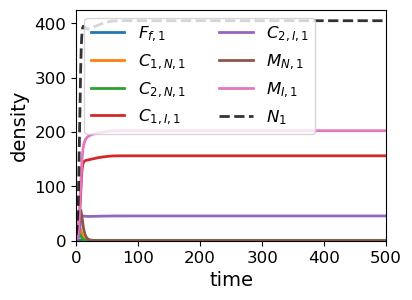

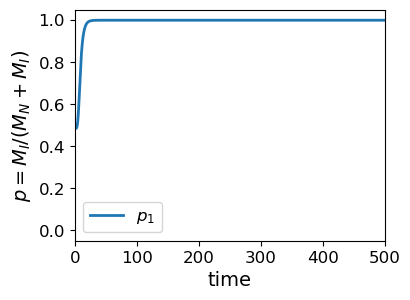

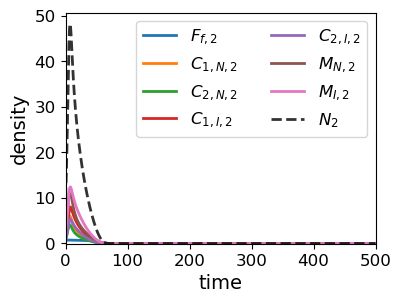

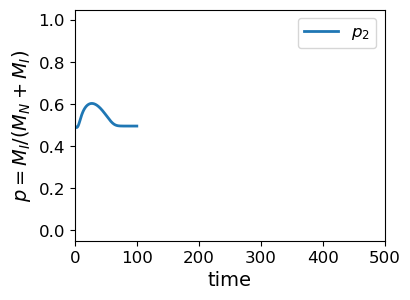

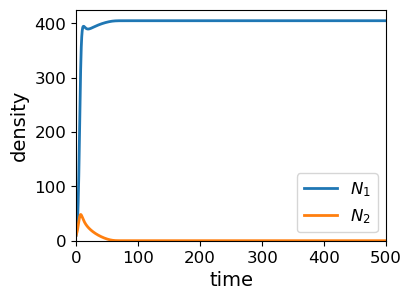

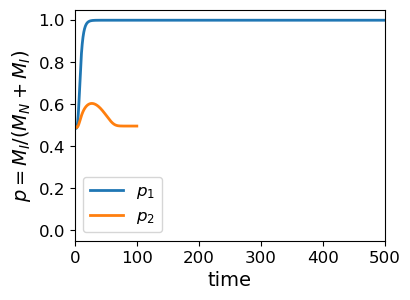

In [5]:
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import mpmath as mp
import numpy as np
from numpy.polynomial import Polynomial as P
from scipy.integrate import solve_ivp
from scipy.ndimage import distance_transform_edt
from scipy.optimize import root
from tqdm.auto import tqdm

# Density and strategy tolerances have different units and purposes.
DENSITY_TOL = 1e-7
MALE_DENSITY_TOL = 1e-12
STRATEGY_TOL = 1e-6
# Finite-time endpoints use looser tolerances than equilibrium classification.
ENDPOINT_DENSITY_TOL = 1e-5
ENDPOINT_STRATEGY_TOL = 1e-3


def strategy_label(p, tol=STRATEGY_TOL):
    if not np.isfinite(p):
        return "undefined"
    return "0" if p <= tol else "1" if p >= 1 - tol else "polymorphic"


def male_strategy_frequency(state, density_tol=DENSITY_TOL):
    """Return frequency only while the species and its male population persist."""
    state = np.asarray(state, dtype=float)
    males = state[5] + state[6]
    present = (state.sum(axis=0) > density_tol) & (males > MALE_DENSITY_TOL)
    return np.divide(state[6], males, out=np.full_like(males, np.nan), where=present)

params = {
    'alpha1': 1.0,
    'beta1': 1.0,
    'gamma1': 0.01,
    'd1': 0.001,
    'b_N1': 2.0,
    's1': 0.1,

    'alpha2': 1.0,
    'beta2': 1.0,
    'gamma2': 0.01,
    'd2': 0.001,
    'b_N2': 1.0,
    's2': 0.1,

    'rho12': 1.0,
    'rho21': 1.0,
}


def two_species_ecoevo_rhs(time, y, params):
    (
        F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1,
        F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2,
    ) = y

    N1 = F_f1 + C1_N1 + C2_N1 + C1_I1 + C2_I1 + M_N1 + M_I1
    N2 = F_f2 + C1_N2 + C2_N2 + C1_I2 + C2_I2 + M_N2 + M_I2

    alpha1 = params['alpha1']
    beta1 = params['beta1']
    gamma1 = params['gamma1']
    d1 = params['d1']
    b_N1 = params['b_N1']
    s1 = params['s1']
    b_I1 = (1.0 - s1) * b_N1

    alpha2 = params['alpha2']
    beta2 = params['beta2']
    gamma2 = params['gamma2']
    d2 = params['d2']
    b_N2 = params['b_N2']
    s2 = params['s2']
    b_I2 = (1.0 - s2) * b_N2

    rho12 = params['rho12']
    rho21 = params['rho21']

    comp1 = d1 * (N1 + rho12 * N2)
    comp2 = d2 * (N2 + rho21 * N1)

    mating_N1 = alpha1 * M_N1 * F_f1
    mating_I1 = alpha1 * M_I1 * F_f1
    mating_N2 = alpha2 * M_N2 * F_f2
    mating_I2 = alpha2 * M_I2 * F_f2

    dF_f1 = -(mating_N1 + mating_I1) + (1.0 + b_N1) * beta1 * C2_N1 + (1.0 + b_I1) * beta1 * C2_I1 - comp1 * F_f1
    dC1_N1 = mating_N1 - (beta1 + comp1 + gamma1 * M_I1) * C1_N1
    dC2_N1 = beta1 * C1_N1 - (beta1 + comp1 + gamma1 * M_I1) * C2_N1
    dC1_I1 = mating_I1 + gamma1 * M_I1 * (C1_N1 + C2_N1 + C2_I1) - (beta1 + comp1) * C1_I1
    dC2_I1 = beta1 * C1_I1 - (beta1 + comp1 + gamma1 * M_I1) * C2_I1
    dM_N1 = b_N1 * beta1 * C2_N1 - comp1 * M_N1
    dM_I1 = b_I1 * beta1 * C2_I1 - comp1 * M_I1

    dF_f2 = -(mating_N2 + mating_I2) + (1.0 + b_N2) * beta2 * C2_N2 + (1.0 + b_I2) * beta2 * C2_I2 - comp2 * F_f2
    dC1_N2 = mating_N2 - (beta2 + comp2 + gamma2 * M_I2) * C1_N2
    dC2_N2 = beta2 * C1_N2 - (beta2 + comp2 + gamma2 * M_I2) * C2_N2
    dC1_I2 = mating_I2 + gamma2 * M_I2 * (C1_N2 + C2_N2 + C2_I2) - (beta2 + comp2) * C1_I2
    dC2_I2 = beta2 * C1_I2 - (beta2 + comp2 + gamma2 * M_I2) * C2_I2
    dM_N2 = b_N2 * beta2 * C2_N2 - comp2 * M_N2
    dM_I2 = b_I2 * beta2 * C2_I2 - comp2 * M_I2

    return np.array([
        dF_f1, dC1_N1, dC2_N1, dC1_I1, dC2_I1, dM_N1, dM_I1,
        dF_f2, dC1_N2, dC2_N2, dC1_I2, dC2_I2, dM_N2, dM_I2,
    ], dtype=float)

# N1=N2=10, p1=p2=0.5; equal female states and equal sex totals.
y0 = np.tile(np.array([1., 1., 1., 1., 1., 2.5, 2.5]), 2)

t_span = (0.0, 500.0)
t_eval = np.linspace(t_span[0], t_span[1], 2000)

sol = solve_ivp(
    lambda time, y: two_species_ecoevo_rhs(time, y, params),
    t_span,
    y0,
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-10,
)

if not sol.success:
    raise RuntimeError(sol.message)

(
    F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1,
    F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2,
) = sol.y

N1 = F_f1 + C1_N1 + C2_N1 + C1_I1 + C2_I1 + M_N1 + M_I1
N2 = F_f2 + C1_N2 + C2_N2 + C1_I2 + C2_I2 + M_N2 + M_I2
p1 = male_strategy_frequency(sol.y[:7])
p2 = male_strategy_frequency(sol.y[7:])

axis_tick_fontsize = 12
axis_label_fontsize = 14

def plot_species(time, species_idx, F_f, C1_N, C2_N, C1_I, C2_I, M_N, M_I, N, p):
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(time, F_f, label=rf'$F_{{f,{species_idx}}}$', lw=2)
    ax.plot(time, C1_N, label=rf'$C_{{1,N,{species_idx}}}$', lw=2)
    ax.plot(time, C2_N, label=rf'$C_{{2,N,{species_idx}}}$', lw=2)
    ax.plot(time, C1_I, label=rf'$C_{{1,I,{species_idx}}}$', lw=2)
    ax.plot(time, C2_I, label=rf'$C_{{2,I,{species_idx}}}$', lw=2)
    ax.plot(time, M_N, label=rf'$M_{{N,{species_idx}}}$', lw=2)
    ax.plot(time, M_I, label=rf'$M_{{I,{species_idx}}}$', lw=2)
    ax.plot(time, N, label=rf'$N_{species_idx}$', lw=2, ls='--', color='black', alpha=0.8)
    ax.set_xlim(time[0], time[-1])
    ax.set_xlabel('time', fontsize=axis_label_fontsize)
    ax.set_ylabel('density', fontsize=axis_label_fontsize)
    ax.set_ylim(bottom=-0.05)
    ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
    ax.legend(ncol=2, frameon=True, fontsize=axis_tick_fontsize)

    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(time, p, label=rf'$p_{species_idx}$', lw=2)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(time[0], time[-1])
    ax.set_xlabel('time', fontsize=axis_label_fontsize)
    ax.set_ylabel(r'$p = M_I / (M_N + M_I)$', fontsize=axis_label_fontsize)
    ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
    ax.legend(frameon=True, fontsize=axis_tick_fontsize)

plot_species(sol.t, 1, F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1, N1, p1)
plot_species(sol.t, 2, F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2, N2, p2)

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(sol.t, N1, label=r'$N_1$', lw=2)
ax.plot(sol.t, N2, label=r'$N_2$', lw=2)
ax.set_ylim(bottom=-0.05)
ax.set_xlim(sol.t[0], sol.t[-1])
ax.set_xlabel('time', fontsize=axis_label_fontsize)
ax.set_ylabel('density', fontsize=axis_label_fontsize)
ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
ax.legend(frameon=True, fontsize=axis_tick_fontsize)

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(sol.t, p1, label=r'$p_1$', lw=2)
ax.plot(sol.t, p2, label=r'$p_2$', lw=2)
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(sol.t[0], sol.t[-1])
ax.set_xlabel('time', fontsize=axis_label_fontsize)
ax.set_ylabel(r'$p = M_I / (M_N + M_I)$', fontsize=axis_label_fontsize)
ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
ax.legend(frameon=True, fontsize=axis_tick_fontsize)

plt.show()


### Setup

In [6]:
"""Equilibrium utilities for the mass-action ODE defined above."""

_boundary_polymorphism_cache = {}
_reduced_state_cache = {}

def _species_state(y, offset):
    return np.asarray(y[offset : offset + 7], dtype=float)


def _fill_species_jacobian(
    J,
    y,
    offset,
    other_offset,
    alpha,
    beta,
    gamma,
    d,
    b_N,
    s,
    rho,
):
    F, C1_N, C2_N, C1_I, C2_I, M_N, M_I = _species_state(y, offset)
    N_self = F + C1_N + C2_N + C1_I + C2_I + M_N + M_I
    N_other = float(np.sum(_species_state(y, other_offset)))
    comp = d * (N_self + rho * N_other)
    b_I = (1.0 - s) * b_N

    local = slice(offset, offset + 7)
    other = slice(other_offset, other_offset + 7)
    row_values = np.array([F, C1_N, C2_N, C1_I, C2_I, M_N, M_I], dtype=float)
    J[offset : offset + 7, other] = -d * rho * row_values[:, None]

    J[offset + 0, local] = [
        -alpha * (M_N + M_I) - comp - d * F,
        -d * F,
        (1.0 + b_N) * beta - d * F,
        -d * F,
        (1.0 + b_I) * beta - d * F,
        -(alpha + d) * F,
        -(alpha + d) * F,
    ]
    J[offset + 1, local] = [
        alpha * M_N - d * C1_N,
        -beta - comp - gamma * M_I - d * C1_N,
        -d * C1_N,
        -d * C1_N,
        -d * C1_N,
        alpha * F - d * C1_N,
        -(gamma + d) * C1_N,
    ]
    J[offset + 2, local] = [
        -d * C2_N,
        beta - d * C2_N,
        -beta - comp - gamma * M_I - d * C2_N,
        -d * C2_N,
        -d * C2_N,
        -d * C2_N,
        -(gamma + d) * C2_N,
    ]
    J[offset + 3, local] = [
        alpha * M_I - d * C1_I,
        gamma * M_I - d * C1_I,
        gamma * M_I - d * C1_I,
        -beta - comp - d * C1_I,
        gamma * M_I - d * C1_I,
        -d * C1_I,
        alpha * F + gamma * (C1_N + C2_N + C2_I) - d * C1_I,
    ]
    J[offset + 4, local] = [
        -d * C2_I,
        -d * C2_I,
        -d * C2_I,
        beta - d * C2_I,
        -beta - comp - gamma * M_I - d * C2_I,
        -d * C2_I,
        -(gamma + d) * C2_I,
    ]
    J[offset + 5, local] = [
        -d * M_N,
        -d * M_N,
        b_N * beta - d * M_N,
        -d * M_N,
        -d * M_N,
        -comp - d * M_N,
        -d * M_N,
    ]
    J[offset + 6, local] = [
        -d * M_I,
        -d * M_I,
        -d * M_I,
        -d * M_I,
        b_I * beta - d * M_I,
        -d * M_I,
        -comp - d * M_I,
    ]


def two_species_analytic_jacobian(y, params):
    """Analytic Jacobian of the full 14-dimensional two-species ODE."""
    y = np.asarray(y, dtype=float)
    J = np.zeros((14, 14), dtype=float)
    _fill_species_jacobian(
        J,
        y,
        offset=0,
        other_offset=7,
        alpha=params["alpha1"],
        beta=params["beta1"],
        gamma=params["gamma1"],
        d=params["d1"],
        b_N=params["b_N1"],
        s=params["s1"],
        rho=params["rho12"],
    )
    _fill_species_jacobian(
        J,
        y,
        offset=7,
        other_offset=0,
        alpha=params["alpha2"],
        beta=params["beta2"],
        gamma=params["gamma2"],
        d=params["d2"],
        b_N=params["b_N2"],
        s=params["s2"],
        rho=params["rho21"],
    )
    return J


def two_species_equilibrium_residual(y, params, rhs_func):
    return rhs_func(0.0, np.asarray(y, dtype=float), params)


def classify_stability_margin(stability_margin, eigen_tol=1e-8):
    if stability_margin < -eigen_tol:
        return "stable"
    if stability_margin > eigen_tol:
        return "unstable"
    return "neutral"


def _species_family(y_species, tol=1e-7):
    F, C1_N, C2_N, C1_I, C2_I, M_N, M_I = np.asarray(y_species, dtype=float)
    N = float(F + C1_N + C2_N + C1_I + C2_I + M_N + M_I)
    if N <= tol:
        return "extinct"
    if M_I <= tol and M_N > tol:
        return "p0"
    if M_N <= tol and M_I > tol:
        return "p1"
    if M_N + M_I <= tol:
        return "no_males"
    return "interior"


def equilibrium_family_2sp(y, tol=1e-7):
    y = np.asarray(y, dtype=float)
    return f"sp1:{_species_family(y[:7], tol)}|sp2:{_species_family(y[7:], tol)}"


def two_species_equilibrium_metrics(y):
    y = np.asarray(y, dtype=float)
    y1 = y[:7]
    y2 = y[7:]
    N1 = float(np.sum(y1))
    N2 = float(np.sum(y2))
    male1 = y1[5] + y1[6]
    male2 = y2[5] + y2[6]
    p1 = float(y1[6] / male1) if male1 > 1e-12 else np.nan
    p2 = float(y2[6] / male2) if male2 > 1e-12 else np.nan
    return {"N1": N1, "N2": N2, "p1": p1, "p2": p2}


def equilibrium_distance_2sp(y1, y2):
    y1 = np.asarray(y1, dtype=float)
    y2 = np.asarray(y2, dtype=float)
    scale = max(1.0, np.linalg.norm(y1, ord=np.inf), np.linalg.norm(y2, ord=np.inf))
    return float(np.linalg.norm(y1 - y2, ord=np.inf) / scale)


def refine_two_species_equilibrium(
    seed,
    params,
    rhs_func,
    root_tol=1e-11,
    residual_tol=1e-7,
    eigen_tol=1e-8,
):
    seed = np.maximum(np.asarray(seed, dtype=float), 0.0)
    sol = root(
        lambda y: two_species_equilibrium_residual(y, params, rhs_func),
        seed,
        jac=lambda y: two_species_analytic_jacobian(y, params),
        method="hybr",
        tol=root_tol,
    )
    y_star = np.asarray(sol.x, dtype=float)
    if np.min(y_star) < -1e-7:
        return None
    y_star = np.maximum(y_star, 0.0)
    y_star[np.abs(y_star) < 1e-10] = 0.0
    for offset in (0, 7):
        if y_star[offset:offset+7].sum() < 1e-7:
            y_star[offset:offset+7] = 0.0

    residual = two_species_equilibrium_residual(y_star, params, rhs_func)
    residual_norm = float(np.linalg.norm(residual, ord=np.inf))
    if (not np.all(np.isfinite(y_star))) or residual_norm > residual_tol:
        return None

    J = two_species_analytic_jacobian(y_star, params)
    if not np.all(np.isfinite(J)):
        return None
    J[np.abs(J) < 1e-12] = 0.0
    eigvals = np.linalg.eigvals(J)
    stability_margin = float(np.max(np.real(eigvals)))
    metrics = two_species_equilibrium_metrics(y_star)
    return {
        "y_star": y_star,
        "residual_norm": residual_norm,
        "jacobian": J,
        "eigvals": eigvals,
        "stability_margin": stability_margin,
        "stability_class": classify_stability_margin(stability_margin, eigen_tol=eigen_tol),
        "family": equilibrium_family_2sp(y_star),
        "stability_method": "mass-action full analytic Jacobian (including boundaries)",
        **metrics,
    }


def _single_species_seed(density_scale, p_guess):
    if density_scale <= 0.0:
        return np.zeros(7, dtype=float)
    n_part = 1.0 - p_guess
    i_part = p_guess
    return np.array(
        [
            10.0 * density_scale,
            1.0 * density_scale * n_part,
            1.0 * density_scale * n_part,
            1.0 * density_scale * i_part,
            1.0 * density_scale * i_part,
            5.0 * density_scale * n_part,
            5.0 * density_scale * i_part,
        ],
        dtype=float,
    )


def reduced_positive_coexistence_states(params):
    """Enumerate physical roots of the mass-action no-infanticide equilibrium.

    At a positive equilibrium M_i=N_i/2. Writing c_i=d_i(N_i+rho_ij*N_j),
    N_i=2*c_i*(beta_i+c_i)^2 /
        (alpha_i*((1+b_Ni)*beta_i^2-(beta_i+c_i)^2)).
    The coupled equations are eliminated to a univariate polynomial, not a
    multidimensional root search. Polynomial roots are checked in the original
    equations and reconstructed full ODE. No small-density root is clipped.
    """
    a1,a2=params['alpha1'],params['alpha2']
    b1,b2=params['beta1'],params['beta2']
    d1,d2=params['d1'],params['d2']
    r1,r2=params['b_N1'],params['b_N2']
    u,v=params['rho12'],params['rho21']
    if min(a1,a2,b1,b2,d1,d2,r1,r2)<=0 or min(u,v)<0:
        raise ValueError('Positive demographic parameters and nonnegative competition required.')
    # Triangular competition is solved as a scalar positive-root equation.
    if u == 0:
        c1=b1*(np.sqrt(a1*(1+r1)/(a1+2*d1))-1)
        if c1<=0:
            return []
        N1=c1/d1
        x=P([0.,1.])
        B=(x+b2)**2
        D=(1+r2)*b2*b2-B
        poly=(x/d2-v*N1)*a2*D-2*x*B
        pairs=[(c1,float(z.real)) for z in poly.roots() if abs(z.imag)<1e-7]
    elif v == 0:
        swapped={}
        for stem in ['alpha','beta','d','b_N','gamma','s']:
            if stem+'1' in params:
                swapped[stem+'1']=params[stem+'2'];swapped[stem+'2']=params[stem+'1']
        swapped.update(rho12=0.,rho21=u)
        return [np.r_[y[7:],y[:7]] for y in reduced_positive_coexistence_states(swapped)]
    else:
        x=P([0.,1.]);B1=(b1+x)**2;D1=(1+r1)*b1*b1-B1
        determinant=1-u*v
        if abs(determinant)<1e-12:
            # c2=(d2*v/d1)c1; divide out the known extinction root c1=0.
            ratio=d2*v/d1
            B2=(b2+ratio*x)**2;D2=(1+r2)*b2*b2-B2
            poly=D1*D2/d1-2*B1*D2/a1-u*2*ratio*B2*D1/a2
            pairs=[(float(z.real),ratio*float(z.real)) for z in poly.roots() if abs(z.imag)<1e-7]
        else:
            A=d2*(x*D1/d1-determinant*2*x*B1/a1)
            Q=u*D1
            B2=(b2*Q+A)**2
            D2=(1+r2)*b2*b2*Q**2-B2
            poly=determinant*2*A*B2-a2*(A/d2-v*x*Q/d1)*D2
            pairs=[]
            for z in poly.roots():
                if abs(z.imag)>1e-7 or abs(Q(z.real))<1e-12:
                    continue
                # Near the upper demographic root, ordinary polynomial roots
                # lose digits through cancellation. Refine the scalar polynomial
                # at 60 digits before reconstructing densities near its poles.
                if z.real <= 0:
                    continue
                with mp.workdps(60):
                    aa1,aa2,bb1,bb2,dd1,dd2,rr1,rr2,uu,vv=[
                        mp.mpf(str(value)) for value in (a1,a2,b1,b2,d1,d2,r1,r2,u,v)]
                    det=1-uu*vv
                    def terms(t):
                        d=(1+rr1)*bb1**2-(bb1+t)**2
                        aa=dd2*(t*d/dd1-det*2*t*(bb1+t)**2/aa1)
                        qq=uu*d
                        return aa,qq
                    def polynomial(t):
                        aa,qq=terms(t)
                        b=(bb2*qq+aa)**2
                        d=(1+rr2)*bb2**2*qq**2-b
                        return det*2*aa*b-aa2*(aa/dd2-vv*t*qq/dd1)*d
                    try:
                        c=mp.findroot(polynomial,(mp.mpf(str(z.real)),mp.mpf(str(z.real))+mp.mpf('1e-10')),
                                      tol=mp.mpf('1e-50'),maxsteps=100)
                        aa,qq=terms(c)
                        pairs.append((float(c),float(aa/qq)))
                    except (ValueError,ZeroDivisionError):
                        continue
    states=[]
    for c1,c2 in pairs:
        upper1=b1*np.expm1(.5*np.log1p(r1))
        upper2=b2*np.expm1(.5*np.log1p(r2))
        if not (1e-10<c1<upper1 and 1e-10<c2<upper2):
            continue
        N1=2*c1*(b1+c1)**2/(a1*((1+r1)*b1*b1-(b1+c1)**2))
        N2=2*c2*(b2+c2)**2/(a2*((1+r2)*b2*b2-(b2+c2)**2))
        if max(abs(c1-d1*(N1+u*N2)),abs(c2-d2*(N2+v*N1)))>1e-7:
            continue
        def state(N,c,a,b,r):
            M=N/2;C2=c*M/(r*b);C1=(b+c)*C2/b
            F=(b+c)*C1/(a*M)
            return np.array([F,C1,C2,0.,0.,M,0.])
        y=np.r_[state(N1,c1,a1,b1,r1),state(N2,c2,a2,b2,r2)]
        if not any(np.max(abs(y-old))<1e-5 for old in states):
            states.append(y)
    return states


def mass_action_boundary_state(params, species_idx, strategy):
    """Exact positive single-species equilibrium for a pure strategy."""
    a=params[f'alpha{species_idx}'];b=params[f'beta{species_idx}']
    d=params[f'd{species_idx}'];r=params[f'b_N{species_idx}']
    gamma=params[f'gamma{species_idx}'] if strategy else 0.
    r=r*(1-params[f's{species_idx}']) if strategy else r
    # (a+2d)[(b+c)^2+gamma*c^2/(2d)]=a*(1+r)*b^2.
    coefficients=[(a+2*d)*(1+gamma/(2*d)),2*b*(a+2*d),b*b*(2*d-a*r)]
    candidates=np.roots(coefficients)
    roots=[float(c.real) for c in candidates if abs(c.imag)<1e-10 and c.real>1e-10]
    if not roots:
        return None
    c=max(roots);N=c/d;M=N/2;k=gamma*M
    C2=c*M/(r*b);C1=(b+c+k)*C2/b
    F=((b+c)*C1-k*C2)/(a*M)
    local=np.array([F,0.,0.,C1,C2,0.,M]) if strategy else np.array([F,C1,C2,0.,0.,M,0.])
    return np.r_[local,np.zeros(7)] if species_idx==1 else np.r_[np.zeros(7),local]


def mass_action_polymorphic_boundary_states(params, species_idx):
    """Find mixed-strategy single-species equilibria in two variables (c,p).

    These are additional seeds, not a replacement for full ODE checks.
    The boundary demographic problem is independent of interspecific rho.
    """
    a,b,g,d,r,s=[params[f'{stem}{species_idx}'] for stem in ['alpha','beta','gamma','d','b_N','s']]
    key=(a,b,g,d,r,s)
    if key in _boundary_polymorphism_cache:
        locals_found=_boundary_polymorphism_cache[key]
    else:
        locals_found=[]
        ri=r*(1-s)
        if 0<s<1:
            cap=b*(np.sqrt(1+r)-1)
            def equations(z):
                c,p=z
                if abs(c)<1e-12:return np.array([1e3,1e3])
                M=c/(2*d);k=g*p*M
                F=c*(b+c+k)**2/(r*b*b*a)
                common=c*(2*b+c+k)/(b*b)
                return [F/M+common*((1-p)/r+p/ri)-1,
                        (a*M+c)*F/(c*M)-((1-p)*(1+r)/r+p*(1+ri)/ri)]
            for fraction in (.2,.5,.8):
                for p_guess in (.1,.5,.9):
                    result=root(equations,[cap*fraction,p_guess],tol=1e-11)
                    c,p=result.x
                    if not (0<c<cap and 1e-7<p<1-1e-7) or np.max(abs(np.array(equations(result.x))))>1e-8:
                        continue
                    M=c/(2*d);MN=(1-p)*M;MI=p*M;k=g*MI
                    F=c*(b+c+k)**2/(r*b*b*a)
                    C2N=c*MN/(r*b);C2I=c*MI/(ri*b)
                    local=np.array([F,(b+c+k)*C2N/b,C2N,(b+c+k)*C2I/b,C2I,MN,MI])
                    if not any(np.max(abs(local-old))<1e-5 for old in locals_found):
                        locals_found.append(local)
        _boundary_polymorphism_cache[key]=locals_found
    return [np.r_[local,np.zeros(7)] if species_idx==1 else np.r_[np.zeros(7),local] for local in locals_found]


def cached_reduced_coexistence_states(params):
    keys = ("alpha1", "alpha2", "beta1", "beta2", "d1", "d2", "b_N1", "b_N2", "rho12", "rho21")
    key = tuple(float(params[k]) for k in keys)
    if key not in _reduced_state_cache:
        _reduced_state_cache[key] = reduced_positive_coexistence_states(params)
    return _reduced_state_cache[key]


def analytic_reduced_equilibria(params):
    """All physical reduced coexistence candidates, with ecological stability."""
    active = [0,1,2,5,7,8,9,12]
    results = []
    for y in cached_reduced_coexistence_states(params):
        residual = float(np.max(np.abs(two_species_ecoevo_rhs(0.0,y,params))))
        if residual > 1e-7:
            raise RuntimeError("Algebraic reduced equilibrium failed its full ODE check.")
        J = two_species_analytic_jacobian(y,params)[np.ix_(active,active)]
        eig = np.linalg.eigvals(J);margin=float(eig.real.max())
        results.append({
            "y_star":y[active], "y_full":y, "N1":float(y[:7].sum()),
            "N2":float(y[7:].sum()), "coexistence":True,
            "residual_norm":residual, "jacobian":J, "eigenvalues":eig,
            "stability_margin":margin, "stability_class":classify_stability_margin(margin),
        })
    return results


### Setup


In [7]:
def params_with_common_s_rho(base_params, s_value, rho_value):
    p = dict(base_params)
    p["s1"] = float(s_value)
    p["s2"] = float(s_value)
    p["rho12"] = float(rho_value)
    p["rho21"] = float(rho_value)
    return p


def _seed_from_equilibrium(eq_or_seed):
    if isinstance(eq_or_seed, dict) and "y_star" in eq_or_seed:
        return np.asarray(eq_or_seed["y_star"], dtype=float)
    return np.asarray(eq_or_seed, dtype=float)


def parse_family(family):
    """
    Example:
        'sp1:p0|sp2:interior' -> ('p0', 'interior')
    """
    fam1 = family.split("|")[0].split(":")[1]
    fam2 = family.split("|")[1].split(":")[1]
    return fam1, fam2


def ecological_label_from_family(family):
    fam1, fam2 = parse_family(family)

    if fam1 == "extinct" and fam2 == "extinct":
        return "both_extinct"
    if fam1 == "extinct":
        return "species2_only"
    if fam2 == "extinct":
        return "species1_only"
    return "coexistence"


def is_coexistence(eq):
    return ecological_label_from_family(eq["family"]) == "coexistence"


def is_stable_full(eq):
    return eq["stability_class"] == "stable"


def two_species_phase_seed_bank(
    previous_equilibria=None,
    upper_equilibria=None,
    extra_seeds=None,
):
    seeds = []

    for group in (previous_equilibria, upper_equilibria):
        if group is not None:
            seeds.extend(_seed_from_equilibrium(item) for item in group)

    if extra_seeds is not None:
        seeds.extend(np.asarray(seed, dtype=float) for seed in extra_seeds)

    # Extinction
    seeds.append(np.zeros(14, dtype=float))

    # A wider seed bank is useful because the system can be multistable.
    for density in (0.1, 1.0, 10.0, 40.0):
        # Single-species boundary seeds
        seeds.append(np.r_[_single_species_seed(density, 0.0), np.zeros(7)])
        seeds.append(np.r_[_single_species_seed(density, 1.0), np.zeros(7)])
        seeds.append(np.r_[np.zeros(7), _single_species_seed(density, 0.0)])
        seeds.append(np.r_[np.zeros(7), _single_species_seed(density, 1.0)])

        # Two-species seeds
        for p1_guess, p2_guess in (
            (0.0, 0.0),
            (1.0, 1.0),
            (0.5, 0.5),
            (1.0, 0.0),
            (0.0, 1.0),
            (0.2, 0.8),
            (0.8, 0.2),
        ):
            seeds.append(
                np.r_[
                    _single_species_seed(density, p1_guess),
                    _single_species_seed(density, p2_guess),
                ]
            )

    return seeds


def find_two_species_equilibria_phase(
    params,
    rhs_func,
    previous_equilibria=None,
    upper_equilibria=None,
    extra_seeds=None,
    dedupe_tol=1e-6,
):
    equilibria = []
    # Exact demographic seeds reduce missed pure-strategy and boundary roots.
    algebraic_seeds = list(cached_reduced_coexistence_states(params))
    local_states = {1: [], 2: []}
    for species_idx in (1, 2):
        boundary_states = []
        for strategy in (0, 1):
            state = mass_action_boundary_state(params, species_idx, strategy)
            if state is not None:
                boundary_states.append(state)
        boundary_states.extend(mass_action_polymorphic_boundary_states(params, species_idx))
        algebraic_seeds.extend(boundary_states)
        local = slice((species_idx - 1) * 7, species_idx * 7)
        local_states[species_idx] = [state[local] for state in boundary_states]
    for local1 in local_states[1]:
        for local2 in local_states[2]:
            algebraic_seeds.append(np.r_[local1,local2])
    extra_seeds = algebraic_seeds + ([] if extra_seeds is None else list(extra_seeds))

    for seed in two_species_phase_seed_bank(
        previous_equilibria=previous_equilibria,
        upper_equilibria=upper_equilibria,
        extra_seeds=extra_seeds,
    ):
        result = refine_two_species_equilibrium(seed, params, rhs_func)
        if result is None:
            continue

        duplicate = False
        for existing in equilibria:
            if result["family"] == existing["family"] and equilibrium_distance_2sp(result["y_star"], existing["y_star"]) < dedupe_tol:
                duplicate = True
                break

        if not duplicate:
            equilibria.append(result)

    # If multistart roots have not found stable coexistence, check the
    # common positive initial condition and refine its trajectory endpoint.
    # This supplements equilibrium existence searches; it does not turn the
    # parameter map into a map of a single initial condition's basin.
    if not any(eq["stability_class"]=="stable" and eq["N1"]>1e-7 and eq["N2"]>1e-7
               for eq in equilibria):
        trajectory=solve_ivp(lambda time,y:rhs_func(time,y,params),(0.,2000.),
            np.tile(np.array([1.,1.,1.,1.,1.,2.5,2.5]),2),
            method="LSODA",rtol=1e-7,atol=1e-10)
        if not trajectory.success:
            raise RuntimeError("Trajectory-assisted equilibrium search failed: "+trajectory.message)
        result=refine_two_species_equilibrium(trajectory.y[:,-1],params,rhs_func)
        if result is not None and not any(result["family"]==eq["family"] and equilibrium_distance_2sp(result["y_star"],eq["y_star"])<dedupe_tol
                                          for eq in equilibria):
            equilibria.append(result)

    family_order = {
        "extinct": 0,
        "p0": 1,
        "interior": 2,
        "p1": 3,
        "no_males": 4,
    }

    def sort_key(item):
        fam1, fam2 = parse_family(item["family"])
        return (
            item["stability_class"] != "stable",
            family_order.get(fam1, 99),
            family_order.get(fam2, 99),
            item["N1"] + item["N2"],
            np.nan_to_num(item["p1"], nan=-1.0),
            np.nan_to_num(item["p2"], nan=-1.0),
        )

    equilibria.sort(key=sort_key)
    return equilibria


def _evolution_label_from_equilibrium(eq):
    return (
        f"sp1:{strategy_label(eq['p1'])}"
        f" | sp2:{strategy_label(eq['p2'])}"
    )


def _best_equilibrium(candidates):
    if not candidates:
        return None
    return min(
        candidates,
        key=lambda eq: (
            np.nan_to_num(eq.get("stability_margin", np.inf), nan=np.inf),
            -(eq.get("N1", 0.0) + eq.get("N2", 0.0)),
        ),
    )


def summarize_simple_ecology_evolution(equilibria):
    stable_full = [eq for eq in equilibria if is_stable_full(eq)]

    stable_coexistence = [eq for eq in stable_full if is_coexistence(eq)]
    stable_species1_only = [
        eq for eq in stable_full
        if ecological_label_from_family(eq["family"]) == "species1_only"
    ]
    stable_species2_only = [
        eq for eq in stable_full
        if ecological_label_from_family(eq["family"]) == "species2_only"
    ]

    has_stable_coexistence = len(stable_coexistence) > 0
    has_stable_species1_only = len(stable_species1_only) > 0
    has_stable_species2_only = len(stable_species2_only) > 0

    if has_stable_coexistence:
        ecology_label = "coexistence"
        selected = _best_equilibrium(stable_coexistence)
    elif has_stable_species1_only and has_stable_species2_only:
        ecology_label = "alternative_exclusion"
        selected = _best_equilibrium(stable_species1_only + stable_species2_only)
    elif has_stable_species1_only:
        ecology_label = "species1_only"
        selected = _best_equilibrium(stable_species1_only)
    elif has_stable_species2_only:
        ecology_label = "species2_only"
        selected = _best_equilibrium(stable_species2_only)
    else:
        ecology_label = "no_stable_state_found"
        selected = _best_equilibrium(stable_full)

    if ecology_label == "coexistence" and selected is not None:
        evolution_label = _evolution_label_from_equilibrium(selected)
    else:
        evolution_label = "non_coexistence"

    return {
        "ecology_label": ecology_label,
        "evolution_label": evolution_label,
        "selected_equilibrium": selected,
        "has_stable_coexistence": has_stable_coexistence,
        "has_stable_species1_only": has_stable_species1_only,
        "has_stable_species2_only": has_stable_species2_only,
    }



def scan_s_rho_plane(base_params, s_values, rho_values, extra_seeds=None, progress=True):
    """Search stable equilibria; rows are s and columns are rho.

    Multistart roots, algebraic seeds and trajectory assistance improve coverage;
    they do not constitute a proof that every full-model equilibrium is found.
    """
    shape = (len(s_values), len(rho_values))
    ecology = np.empty(shape, dtype=object)
    evolution = np.empty(shape, dtype=object)
    selected = [[None for _ in rho_values] for _ in s_values]
    grid = [[None for _ in rho_values] for _ in s_values]
    coexistence = np.zeros(shape, dtype=bool)
    species1 = np.zeros(shape, dtype=bool)
    species2 = np.zeros(shape, dtype=bool)
    with tqdm(total=ecology.size, desc="Scanning (s, rho)", unit="point", disable=not progress) as bar:
        for i, s_value in enumerate(s_values):
            indices = range(len(rho_values)) if i % 2 == 0 else range(len(rho_values) - 1, -1, -1)
            horizontal = None
            for j in indices:
                p = params_with_common_s_rho(base_params, s_value, rho_values[j])
                eqs = find_two_species_equilibria_phase(
                    p, two_species_ecoevo_rhs, previous_equilibria=horizontal,
                    upper_equilibria=grid[i-1][j] if i else None, extra_seeds=extra_seeds,
                )
                grid[i][j] = horizontal = eqs
                summary = summarize_simple_ecology_evolution(eqs)
                ecology[i, j] = summary["ecology_label"]
                evolution[i, j] = summary["evolution_label"]
                selected[i][j] = summary["selected_equilibrium"]
                coexistence[i, j] = summary["has_stable_coexistence"]
                species1[i, j] = summary["has_stable_species1_only"]
                species2[i, j] = summary["has_stable_species2_only"]
                bar.update(1)
    return {
        "s_values": np.asarray(s_values), "rho_values": np.asarray(rho_values),
        "ecology_labels": ecology, "evolution_labels": evolution,
        "ecology_counts": Counter(ecology.ravel()), "evolution_counts": Counter(evolution.ravel()),
        "stable_coexistence": coexistence, "stable_species1_only": species1,
        "stable_species2_only": species2, "selected_equilibria": selected,
        "equilibria_grid": grid, "params": dict(base_params), "model": "alldens_mass_action",
        "stability_method": "full analytic mass-action Jacobian including extinction boundaries",
    }


### Full-model scan of the $(s,\rho)$ plane

Compute the full-model equilibria and retain the scan results in memory. No result files are written.


In [8]:
# Keep 101 x 101 for the final diagrams; reduce GRID_SIZE for a quick check.
GRID_SIZE = 101
s_values_2d = np.linspace(0.0, 1.0, GRID_SIZE)
rho_values_2d = np.linspace(0.0, 1.0, GRID_SIZE)
scan_grids = {"s_values": s_values_2d, "rho_values": rho_values_2d}
phase_diagram_2sp_s_rho_scan = scan_s_rho_plane(
    params, s_values_2d, rho_values_2d, extra_seeds=[y0, sol.y[:, -1]],
)
print("Ecological outcomes:", phase_diagram_2sp_s_rho_scan["ecology_counts"])
print("Evolutionary outcomes:", phase_diagram_2sp_s_rho_scan["evolution_counts"])


Scanning (s, rho):   0%|          | 0/10201 [00:00<?, ?point/s]

Ecological outcomes: Counter({'coexistence': 8631, 'alternative_exclusion': 1570})
Evolutionary outcomes: Counter({'sp1:1 | sp2:1': 3567, 'sp1:1 | sp2:polymorphic': 2193, 'non_coexistence': 1570, 'sp1:0 | sp2:0': 1285, 'sp1:polymorphic | sp2:0': 1153, 'sp1:polymorphic | sp2:polymorphic': 433})


### Coexistence without infanticide: mass-action equilibrium conditions

At a positive equilibrium, the total male density of each species satisfies $M_i=N_i/2$. Defining $c_i=d_i(N_i+\rho_{ij}N_j)$ gives

$$
N_i=\frac{2c_i(\beta_i+c_i)^2}{\alpha_i[(1+b_{N,i})\beta_i^2-(\beta_i+c_i)^2]}
$$

The coupled conditions are reduced to a univariate polynomial, and candidate real roots are checked against the original conditions. Closely spaced roots are refined using high-precision arithmetic.
The ecological stability of positive coexistence candidates is determined using the analytic Jacobian of the eight-variable non-infanticidal subsystem.


In [9]:
coexistence = np.zeros((len(s_values_2d), len(rho_values_2d)), dtype=bool)
equilibria_by_rho = []
for j, rho in enumerate(rho_values_2d):
    eqs = analytic_reduced_equilibria(dict(params, rho12=float(rho), rho21=float(rho)))
    equilibria_by_rho.append(eqs)
    # With no infanticidal males, the demographic equilibrium is independent of s.
    coexistence[:, j] = any(eq["stability_class"] == "stable" for eq in eqs)
phase_diagram_2sp_s_rho_no_infanticide_reduced_result = {
    **scan_grids, "coexistence": coexistence, "equilibria_by_rho": equilibria_by_rho,
    "params": dict(params), "model": "alldens_mass_action",
    "method": "physical polynomial roots, high-precision refinement and analytic ecological Jacobian",
}
print("Stable reduced coexistence points:",
      int(phase_diagram_2sp_s_rho_no_infanticide_reduced_result["coexistence"].sum()))


Stable reduced coexistence points: 5252


### Expansion of the coexistence region through infanticide evolution

Compare the full-model and reduced-model results held in memory to plot ecological and evolutionary outcomes. Categories are distinguished by color rather than hatching.


### Phase-diagram plotting utilities

Define the classification and plotting functions used with the in-memory scan results.


In [10]:
ECOLOGY_COLORS = {
    "coexistence_without_infanticide":"#a0cbe8",
    "coexistence_gained_by_infanticide":"#d4a6c8",
    "species1_only":"#ffbe7d", "species2_only":"#8cd17d",
    "alternative_exclusion":"#d7b5a6", "no_stable_state_found":"#f7e1a0",
    "coexistence_baseline_conflict":"#d1e7dd",
}
ECOLOGY_NAMES = {
    "coexistence_without_infanticide":"coexistence without infanticide",
    "coexistence_gained_by_infanticide":"coexistence gained by infanticide evolution",
    "species1_only":"species 2 exclusion", "species2_only":"species 1 exclusion",
    "alternative_exclusion":"alternative exclusion",
    "no_stable_state_found":"no stable equilibrium found",
    "coexistence_baseline_conflict":"coexistence: baseline classification conflict",
}
EVOLUTION_PALETTE = [
    "#4e79a7","#f28e2b","#e15759","#76b7b2","#59a14f",
    "#edc949","#af7aa1","#ff9da7","#9c755f","#b6992d",
    "#86bcb6","#f1ce63","#e19d9a","#fabfd2","#8f63a6",
    "#c7a78d","#2f4b7c","#003f5c","#bc5090","#58508d",
]


def evolution_outcome(eq, density_tol=DENSITY_TOL, strategy_tol=STRATEGY_TOL):
    present1=eq["N1"]>density_tol;present2=eq["N2"]>density_tol
    if present1 and present2:
        return f"sp1:{strategy_label(eq['p1'], strategy_tol)} | sp2:{strategy_label(eq['p2'], strategy_tol)}"
    if present1:
        return f"species2_excluded | sp1:{strategy_label(eq['p1'], strategy_tol)}"
    if present2:
        return f"species1_excluded | sp2:{strategy_label(eq['p2'], strategy_tol)}"
    return "both_extinct"


def plane_outcome_grids(scan,reduced_mask):
    ecology=np.asarray(scan["ecology_labels"],dtype=object).copy()
    evolution=np.empty(ecology.shape,dtype=object)
    for i,j in np.ndindex(ecology.shape):
        eq=scan["selected_equilibria"][i][j]
        if ecology[i,j]=="coexistence":
            if reduced_mask[i,j]: ecology[i,j]="coexistence_without_infanticide"
            elif strategy_label(eq['p1'])!="0" or strategy_label(eq['p2'])!="0":
                ecology[i,j]="coexistence_gained_by_infanticide"
            else: ecology[i,j]="coexistence_baseline_conflict"
            evolution[i,j]=evolution_outcome(eq)
        elif ecology[i,j]=="alternative_exclusion":
            stable=[e for e in scan["equilibria_grid"][i][j] if e["stability_class"]=="stable"]
            states=[]
            for species_idx in (1,2):
                local=sorted({strategy_label(e[f'p{species_idx}']) for e in stable
                              if e[f'N{species_idx}']>1e-7 and e[f'N{3-species_idx}']<=1e-7})
                states.append('/'.join(local))
            evolution[i,j]=f"alternative exclusion | sp1:{states[0]} | sp2:{states[1]}"
        else:
            evolution[i,j]=evolution_outcome(eq) if eq is not None else "no_stable_state_found"
    return ecology,evolution


def evolution_color_map(labels):
    preferred={
        "sp1:0 | sp2:0":"#76b7b2", "sp1:0 | sp2:1":"#2f4b7c",
        "sp1:0 | sp2:polymorphic":"#003f5c",
        "sp1:1 | sp2:0":"#59a14f", "sp1:1 | sp2:1":"#edc949",
        "sp1:1 | sp2:polymorphic":"#af7aa1",
        "sp1:polymorphic | sp2:0":"#ff9da7",
        "sp1:polymorphic | sp2:1":"#b6992d",
        "sp1:polymorphic | sp2:polymorphic":"#9c755f",
        "alternative exclusion | sp1:0 | sp2:0":"#4e79a7",
        "alternative exclusion | sp1:0 | sp2:1":"#86bcb6",
        "alternative exclusion | sp1:0 | sp2:polymorphic":"#f1ce63",
        "alternative exclusion | sp1:1 | sp2:0":"#c7a78d",
        "alternative exclusion | sp1:1 | sp2:1":"#f28e2b",
        "alternative exclusion | sp1:1 | sp2:polymorphic":"#8f63a6",
        "alternative exclusion | sp1:polymorphic | sp2:0":"#e15759",
        "alternative exclusion | sp1:polymorphic | sp2:1":"#e19d9a",
        "alternative exclusion | sp1:polymorphic | sp2:polymorphic":"#fabfd2",
    }
    ordered=[label for label in preferred if label in labels]+sorted(set(labels)-set(preferred))
    if len(ordered)>len(EVOLUTION_PALETTE):
        raise ValueError("Too many outcome categories for the declared palette.")
    colors={};used=set()
    # Reserve established colors before assigning additional outcomes.
    reserved={preferred[label] for label in ordered if label in preferred}
    for label in ordered:
        color=preferred.get(label)
        if color is None:
            color=next(c for c in EVOLUTION_PALETTE if c not in used and c not in reserved)
        colors[label]=color;used.add(color)
    assert not used & set(ECOLOGY_COLORS.values())
    return ordered,colors


def grid_edges(values):
    """Convert increasing scan centers to cell edges for a faithful parameter map."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.all(np.isfinite(values)) or np.any(np.diff(values) <= 0):
        raise ValueError("At least two finite increasing grid coordinates are required.")
    return np.r_[values[0] - (values[1] - values[0]) / 2,
                 (values[:-1] + values[1:]) / 2,
                 values[-1] + (values[-1] - values[-2]) / 2]


def draw_outcome_plane(grid,x,y,labels,colors,names,xlabel,ylabel,title):
    codes=np.zeros(grid.shape,dtype=int)
    for number,label in enumerate(labels): codes[grid==label]=number
    cmap=ListedColormap([colors[label] for label in labels])
    norm=BoundaryNorm(np.arange(-.5,len(labels)+.5),len(labels))
    fig,ax=plt.subplots(figsize=(3.,3.))
    ax.pcolormesh(grid_edges(x), grid_edges(y), codes, shading="flat", cmap=cmap, norm=norm)
    ax.set_xlim(x[0],x[-1]);ax.set_ylim(y[0],y[-1])
    ax.set_xlabel(xlabel,fontsize=14);ax.set_ylabel(ylabel,fontsize=14)
    ax.set_xticks(np.arange(0,1.01,.2));ax.set_yticks(np.arange(0,1.01,.2))
    ax.tick_params(labelsize=12);ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=colors[label],edgecolor="black",label=names.get(label,label))
                       for label in labels],loc="upper left",bbox_to_anchor=(1.02,1),fontsize=8)
    return fig,ax



### Redraw the figures from in-memory results

After running both scan cells, rerun this cell alone to update the colors and formatting. It does not execute a parameter scan or read or write result files.


Ecological outcomes: {'alternative_exclusion': np.int64(1570), 'coexistence_gained_by_infanticide': np.int64(3379), 'coexistence_without_infanticide': np.int64(5252)}
Evolutionary outcomes: {'alternative exclusion | sp1:0 | sp2:0': np.int64(1176), 'alternative exclusion | sp1:1 | sp2:1': np.int64(274), 'alternative exclusion | sp1:polymorphic | sp2:0': np.int64(120), 'sp1:0 | sp2:0': np.int64(1285), 'sp1:1 | sp2:1': np.int64(3567), 'sp1:1 | sp2:polymorphic': np.int64(2193), 'sp1:polymorphic | sp2:0': np.int64(1153), 'sp1:polymorphic | sp2:polymorphic': np.int64(433)}


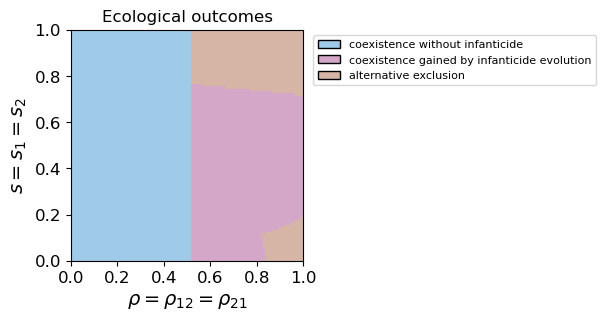

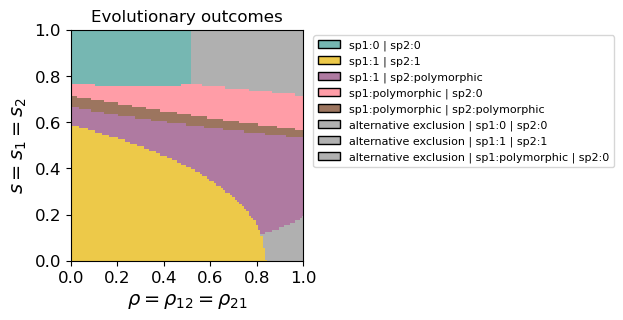

In [11]:
full_scan = phase_diagram_2sp_s_rho_scan
reduced_scan = phase_diagram_2sp_s_rho_no_infanticide_reduced_result
if not np.array_equal(full_scan["s_values"],reduced_scan["s_values"]) or not np.array_equal(full_scan["rho_values"],reduced_scan["rho_values"]):
    raise ValueError("Full and reduced scan grids differ.")
for key in ("alpha1","alpha2","beta1","beta2","d1","d2","b_N1","b_N2"):
    if full_scan["params"][key]!=reduced_scan["params"][key]:
        raise ValueError("Full and reduced demographic parameters differ.")
ecological_grid,evolutionary_grid=plane_outcome_grids(full_scan,reduced_scan["coexistence"])
labels_ecology=[label for label in ECOLOGY_COLORS if np.any(ecological_grid==label)]
labels_evolution,colors_evolution=evolution_color_map(set(evolutionary_grid.ravel()))
# Gray exclusion outcomes in this first evolutionary figure only.
for label in labels_evolution:
    if label.startswith("alternative exclusion |"):
        colors_evolution[label]="#b0b0b0"
fig_difference,ax_difference=draw_outcome_plane(
    ecological_grid,full_scan["rho_values"],full_scan["s_values"],labels_ecology,ECOLOGY_COLORS,ECOLOGY_NAMES,
    r"$\rho=\rho_{12}=\rho_{21}$",r"$s=s_1=s_2$","Ecological outcomes")
fig_coexistence_evolution,ax_coexistence_evolution=draw_outcome_plane(
    evolutionary_grid,full_scan["rho_values"],full_scan["s_values"],labels_evolution,colors_evolution,{},
    r"$\rho=\rho_{12}=\rho_{21}$",r"$s=s_1=s_2$","Evolutionary outcomes")
print("Ecological outcomes:",dict(zip(*np.unique(ecological_grid,return_counts=True))))
print("Evolutionary outcomes:",dict(zip(*np.unique(evolutionary_grid,return_counts=True))))
plt.show()


### Eco-evolutionary dynamics at representative points in each region

Choose a representative point with simple parameter values from each detected region, and plot population densities and strategy frequencies separately. All regions use the same initial conditions: $N_1=N_2=10$ and $p_1=p_2=0.5$, with density 1 in each of the five female states and density 2.5 for each of the two male types.
Display trajectories over $0\le t\le500$, and extend the integration separately to check convergence. Record the region classification based on the existence of locally stable equilibria separately from the outcome actually reached from the common initial conditions.


region_01: map=sp1:0 | sp2:0; observed=sp1:0 | sp2:0; s=0.9, rho=0.4, converged=True


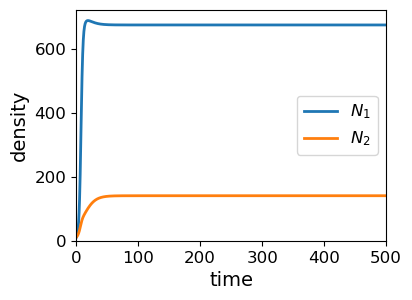

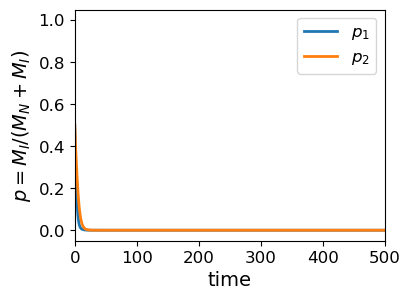

region_02: map=sp1:1 | sp2:1; observed=sp1:1 | sp2:1; s=0.2, rho=0.4, converged=True


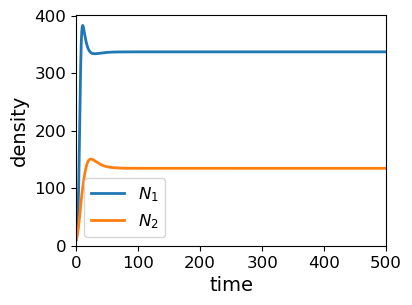

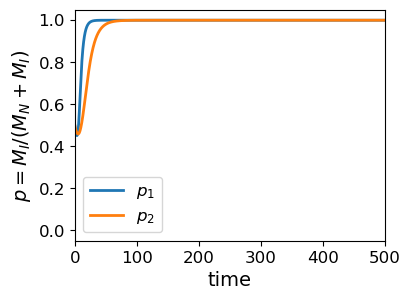

region_03: map=sp1:1 | sp2:polymorphic; observed=sp1:1 | sp2:polymorphic; s=0.4, rho=0.8, converged=True


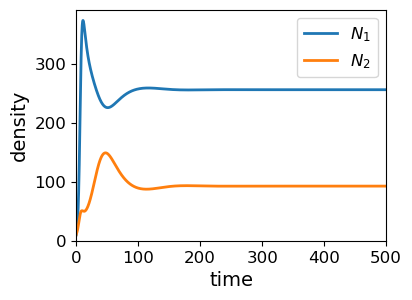

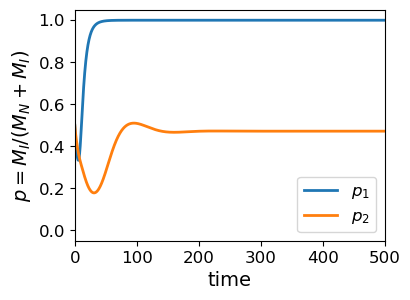

region_04: map=sp1:polymorphic | sp2:0; observed=sp1:polymorphic | sp2:0; s=0.7, rho=0.5, converged=True


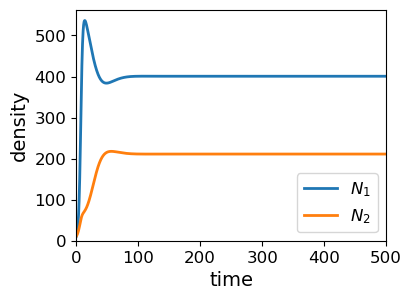

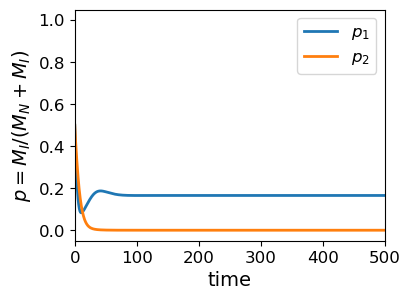

region_05: map=sp1:polymorphic | sp2:polymorphic; observed=sp1:polymorphic | sp2:polymorphic; s=0.6, rho=0.6, converged=True


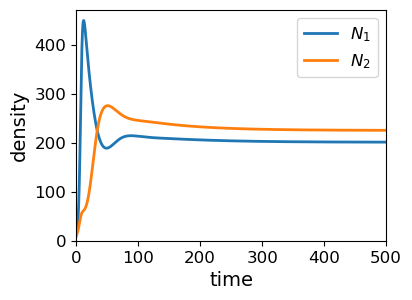

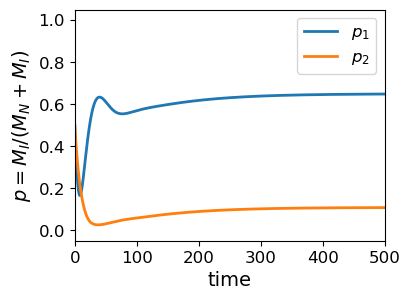

region_06: map=alternative exclusion | sp1:0 | sp2:0; observed=species2_excluded | sp1:0; s=0.9, rho=0.7, converged=True


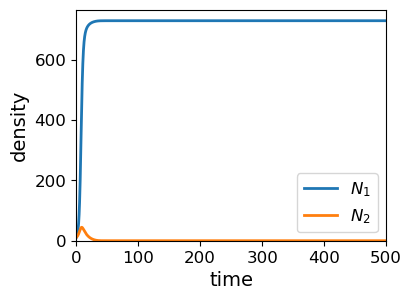

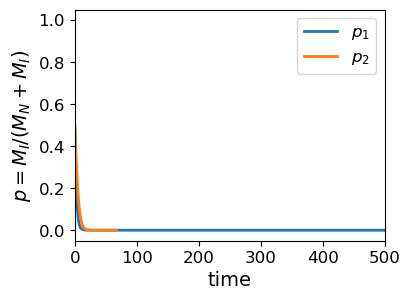

region_07: map=alternative exclusion | sp1:1 | sp2:1; observed=species2_excluded | sp1:1; s=0.1, rho=0.9, converged=True


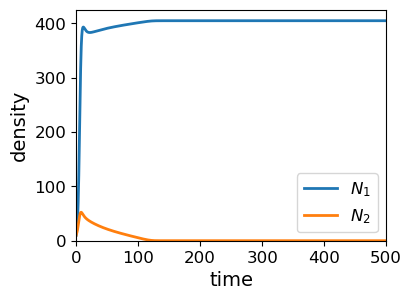

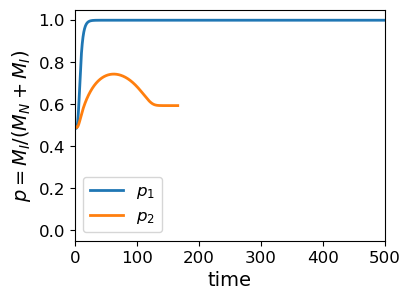

region_08: map=alternative exclusion | sp1:polymorphic | sp2:0; observed=species2_excluded | sp1:polymorphic; s=0.75, rho=0.8, converged=True


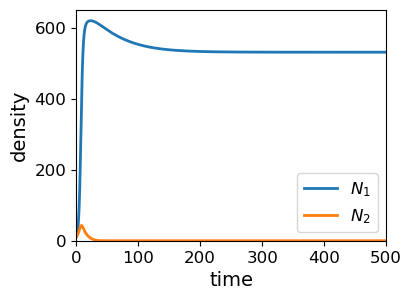

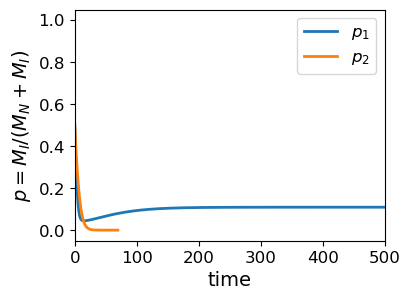

In [12]:
REGION_DISPLAY_END=500.0
region_dynamics_results={}

def decimal_complexity(value):
    if np.isclose(value,0) or np.isclose(value,1): return 0
    if np.isclose(value*10,round(value*10)): return 1
    if np.isclose(value*20,round(value*20)): return 2
    return 3


for number,label in enumerate(labels_evolution,start=1):
    mask=evolutionary_grid==label
    distances=distance_transform_edt(np.pad(mask,1))[1:-1,1:-1]
    candidates=np.argwhere(mask)
    candidates=candidates[distances[mask]>=min(2.0,float(distances.max()))]
    def score(point):
        i,j=point;a=decimal_complexity(full_scan['s_values'][i]);b=decimal_complexity(full_scan['rho_values'][j])
        return max(a,b),a+b,-distances[i,j],abs(full_scan['s_values'][i]-.5)+abs(full_scan['rho_values'][j]-.5)
    i,j=min(candidates,key=score)
    p=dict(full_scan['params'],s1=float(full_scan['s_values'][i]),s2=float(full_scan['s_values'][i]),
           rho12=float(full_scan['rho_values'][j]),rho21=float(full_scan['rho_values'][j]))
    initial=np.tile(np.array([1.,1.,1.,1.,1.,2.5,2.5]),2)
    horizon=1000.
    while True:
        times=np.unique(np.r_[np.linspace(0,REGION_DISPLAY_END,2000),np.linspace(REGION_DISPLAY_END,horizon,2000)])
        sol_region=solve_ivp(lambda t,y:two_species_ecoevo_rhs(t,y,p),(0,horizon),initial,
                             method='LSODA',t_eval=times,rtol=1e-8,atol=1e-11)
        if not sol_region.success:raise RuntimeError(sol_region.message)
        endpoint=sol_region.y[:,-1]
        residual=float(np.max(abs(two_species_ecoevo_rhs(horizon,endpoint,p))))/max(1.,float(np.max(endpoint)))
        if residual<1e-7 or horizon>=16000:break
        horizon*=2
    # Classify the observed endpoint separately from the equilibrium-existence map.
    metrics=two_species_equilibrium_metrics(np.maximum(endpoint,0))
    actual=evolution_outcome(metrics, density_tol=ENDPOINT_DENSITY_TOL,
                             strategy_tol=ENDPOINT_STRATEGY_TOL)
    values=np.maximum(sol_region.y,0)
    populations=[values[:7].sum(axis=0),values[7:].sum(axis=0)]
    frequencies=[male_strategy_frequency(values[offset:offset+7]) for offset in (0,7)]
    slug=f'region_{number:02d}'
    fig_N,ax_N=plt.subplots(figsize=(4,3))
    for k in range(2):ax_N.plot(sol_region.t,populations[k],label=rf'$N_{k+1}$',lw=2)
    ax_N.set_xlim(0,REGION_DISPLAY_END);ax_N.set_ylim(bottom=-.05)
    ax_N.set_xlabel('time',fontsize=14);ax_N.set_ylabel('density',fontsize=14)
    ax_N.tick_params(labelsize=12);ax_N.legend(frameon=True,fontsize=12)
    fig_p,ax_p=plt.subplots(figsize=(4,3))
    for k in range(2):ax_p.plot(sol_region.t,frequencies[k],label=rf'$p_{k+1}$',lw=2)
    ax_p.set_xlim(0,REGION_DISPLAY_END);ax_p.set_ylim(-.05,1.05)
    ax_p.set_xlabel('time',fontsize=14);ax_p.set_ylabel(r'$p = M_I / (M_N + M_I)$',fontsize=14)
    ax_p.tick_params(labelsize=12);ax_p.legend(frameon=True,fontsize=12)
    record={"region":number,"map_label":label,"actual_endpoint_label":actual,"params":p,
            "y0":initial,"trajectory":sol_region,"relative_rhs_norm":residual,
            "converged":residual<1e-7}
    region_dynamics_results[label]=record
    print(f"{slug}: map={label}; observed={actual}; s={p['s1']:g}, rho={p['rho12']:g}, converged={record['converged']}")
    plt.show()
